# Diffusion of N particles in a box with receptors

Course assignment. Same lattice simulation as in `diffusion_in_a_box.ipynb`, with 20 fixed receptors that can trap a particle sitting on them with probability `pon` per step and release it with probability `poff` per step. The questions are the ones given in the assignment. The functions in `diffusion_box.py` and `libplot_diff.py` were provided by the course.

Q1: In a situation of CLOSED BOX, set RECEPTORS=True and set t_receptors so they appear after equilibrium is set. Choose a number of receptors nrec 100 times less than the N diffusing particles. Look at the history of occupation of each receptor after enough simulation steps. In case use cell below to save the history and load txt in another notebook. Sum each step of the history to get the instant overall occupation of receptors of every step, plot the histogram and observe the mean occupancy of the receptors at the equilibrium.

waiting for equilibrium...
ok, now turning on receptors
step 0/10000
step 1000/10000
step 2000/10000
step 3000/10000
step 4000/10000
step 5000/10000
step 6000/10000
step 7000/10000
step 8000/10000
step 9000/10000


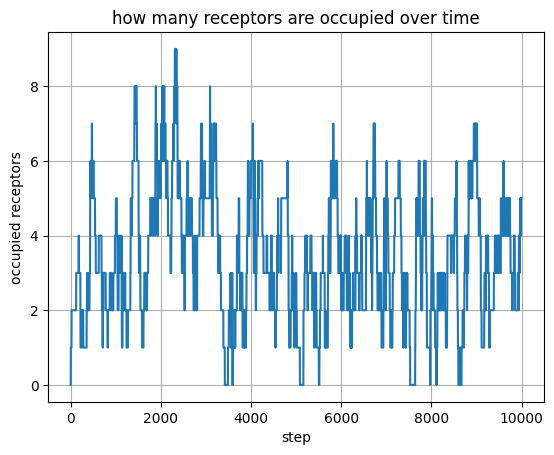

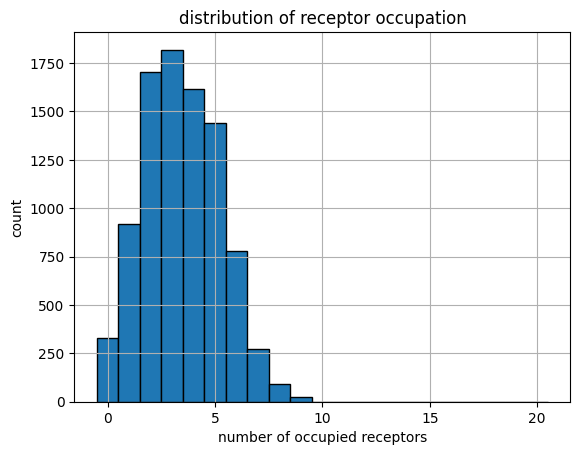

mean occupancy per receptor: 0.172 (out of 1.0)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import diffusion_box as db
import libplot_diff as dl


N = 2000
L = 100
resol = 50
averages = 100
nrec = 20
pon = 0.01
poff = 0.01

x_rec = np.arange(0, L, np.int32(L / nrec))
y_rec = L / 2 * np.ones(len(x_rec))


coord = db.create_in_point(N, [int(L/2), int(L/2)])
coord_rec = db.create_receptors(x_rec, y_rec)


print("waiting for equilibrium...")
for step in range(5000):
    coord = db.diffusione(coord)
    coord = db.p_boundary(coord, L)

print("ok, now turning on receptors")


history = []

for step in range(10000):
    coord, coord_rec = db.escape(coord, coord_rec, poff)
    history.append(np.array(coord_rec[:, 2]))  # 0 = free, 1 = occupied

    coord = db.diffusione(coord)
    coord = db.p_boundary(coord, L)
    coord, coord_rec = db.receptors(coord, coord_rec, pon)
    if step % 1000 == 0:
        print(f"step {step}/10000")

history = np.array(history)

total_occupation = history.sum(axis=1)


plt.figure()
plt.plot(total_occupation)
plt.xlabel("step")
plt.ylabel("occupied receptors")
plt.title("how many receptors are occupied over time")
plt.grid(True)
plt.show()


plt.figure()
plt.hist(total_occupation[1000:], bins=range(nrec + 2), align='left', edgecolor='black')
plt.xlabel("number of occupied receptors")
plt.ylabel("count")
plt.title("distribution of receptor occupation")
plt.grid(True)
plt.show()


mean_per_receptor = history[1000:].mean(axis=0)
print(f"mean occupancy per receptor: {mean_per_receptor.mean():.3f} (out of 1.0)")

For this question I set up the closed box simulation with receptors appearing after equilibrium. I first let the particles spread out for 5000 steps without any receptors, and then I turned them on. The receptors are placed in a line in the middle of the box and there are 20 of them, which is 100 times less than the 2000 particles. Once the receptors appeared I recorded the occupation state of each one at every step — either 0 if it was free or 1 if it had a particle trapped.

What I found was that the occupation starts at zero and within a few hundred steps rises to a level around which it then fluctuates (between 0 and 9 occupied receptors). The histogram shows that most of the time 2 to 5 of the 20 receptors are occupied, with a peak at 3 and a tail towards higher values. The mean occupancy I got was 0.17, meaning each receptor is occupied about 17% of the time, or about 3.4 receptors out of 20 on average.

At first I expected about 50%, because I set pon and poff to the same value. But this is not right: poff acts at every step on an occupied receptor, while pon only acts when a particle is actually sitting on the receptor site. With 2000 particles on a lattice of about 100 × 100 sites, a given site has a particle on it only about 20% of the time. So the chance per step that a free receptor gets filled is about 0.2 × 0.01 = 0.002, against 0.01 for an occupied one to be emptied. The expected occupancy is then 0.002 / (0.002 + 0.01) ≈ 0.17, which is what the simulation gives.

Q2: Try to run the same simulation (do not change pon and poff or the number of receptors) with different choices of N (number of particles). What does it happems to the mean occupancy? Can you relate it to the concept of affinity? What happens if you change pon and poff?

running with N=200...
  mean occupancy: 0.016
running with N=500...
  mean occupancy: 0.055
running with N=1000...
  mean occupancy: 0.090
running with N=2000...
  mean occupancy: 0.135
running with N=5000...
  mean occupancy: 0.329


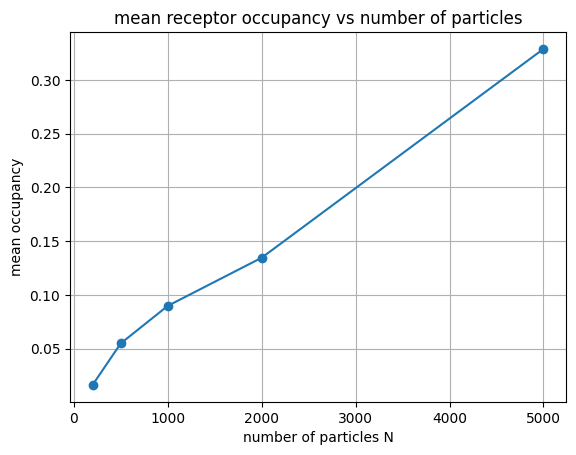


summary:
  N=200: mean occupancy = 0.016
  N=500: mean occupancy = 0.055
  N=1000: mean occupancy = 0.090
  N=2000: mean occupancy = 0.135
  N=5000: mean occupancy = 0.329


In [2]:
L = 100
resol = 50
nrec = 20
pon = 0.01
poff = 0.01

x_rec = np.arange(0, L, np.int32(L / nrec))
y_rec = L / 2 * np.ones(len(x_rec))

N_values = [200, 500, 1000, 2000, 5000]
mean_occupancies = []

for N in N_values:
    print(f"running with N={N}...")

    coord = db.create_in_point(N, [int(L/2), int(L/2)])
    coord_rec = db.create_receptors(x_rec, y_rec)

    for step in range(5000):
        coord = db.diffusione(coord)
        coord = db.p_boundary(coord, L)

    history = []
    for step in range(5000):
        coord, coord_rec = db.escape(coord, coord_rec, poff)
        history.append(np.array(coord_rec[:, 2]))
        coord = db.diffusione(coord)
        coord = db.p_boundary(coord, L)
        coord, coord_rec = db.receptors(coord, coord_rec, pon)

    history = np.array(history)

    mean_occ = history[1000:].mean()
    mean_occupancies.append(mean_occ)
    print(f"  mean occupancy: {mean_occ:.3f}")

plt.figure()
plt.plot(N_values, mean_occupancies, 'o-')
plt.xlabel("number of particles N")
plt.ylabel("mean occupancy")
plt.title("mean receptor occupancy vs number of particles")
plt.grid(True)
plt.show()

print("\nsummary:")
for N, occ in zip(N_values, mean_occupancies):
    print(f"  N={N}: mean occupancy = {occ:.3f}")

I ran the same simulation as before but this time I changed the number of particles N and kept everything else the same — same pon, same poff, same number of receptors. I tried five different values of N: 200, 500, 1000, 2000 and 5000. What I found was that as N increases the mean occupancy of the receptors also increases, from 0.016 at N=200 to 0.33 at N=5000. With very few particles the receptors are mostly empty because not many particles are around to get trapped. As I add more particles the receptors are occupied more often. In this range the occupancy is still far from saturation; I expect it to get close to 1 only for much larger N.

This behaviour reminds me of what happens in biology when you increase the concentration of a ligand — at low concentrations only a few receptors are bound, and as the concentration increases more and more receptors get occupied until they saturate. I think this is what the assignment means by affinity: how much occupancy the receptor reaches for a given concentration of ligand.

The values are noisy. For N=2000 I got 0.135 here, 0.172 in question 1 and 0.178 in question 3, so differences of a few percent between runs are not meaningful.

I did not change pon and poff in this notebook. From the argument in question 1 I expect that with a higher pon the particles get trapped more easily so the occupancy goes up, with a higher poff they escape more easily so the occupancy goes down, and that the ratio between pon and poff is what controls the occupancy for a given N.

Q3: For a meaningful choice of pon and poff, plot the main occupancy vs N. Comment and describe the curve you plotted. Find the N that has 50% of occupancy level. 

running with N=100...
  mean occupancy: 0.015
running with N=200...
  mean occupancy: 0.021
running with N=500...
  mean occupancy: 0.058
running with N=800...
  mean occupancy: 0.071
running with N=1000...
  mean occupancy: 0.066
running with N=1500...
  mean occupancy: 0.105
running with N=2000...
  mean occupancy: 0.178
running with N=3000...
  mean occupancy: 0.215
running with N=5000...
  mean occupancy: 0.346
running with N=8000...
  mean occupancy: 0.431


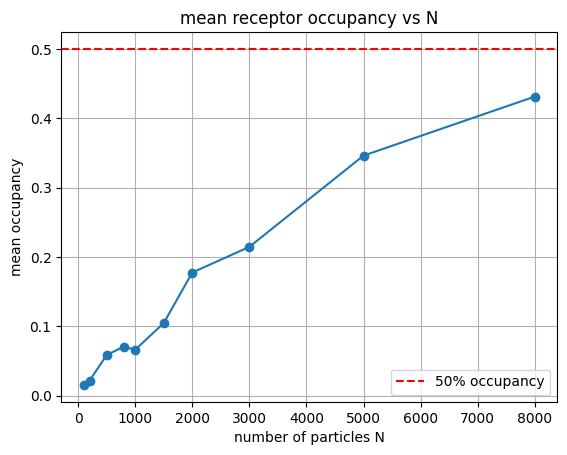


the N closest to 50% occupancy is N=8000
with mean occupancy = 0.431


In [3]:
L = 100
nrec = 20
pon = 0.01
poff = 0.01

x_rec = np.arange(0, L, np.int32(L / nrec))
y_rec = L / 2 * np.ones(len(x_rec))

N_values = [100, 200, 500, 800, 1000, 1500, 2000, 3000, 5000, 8000]
mean_occupancies = []

for N in N_values:
    print(f"running with N={N}...")

    coord = db.create_in_point(N, [int(L/2), int(L/2)])
    coord_rec = db.create_receptors(x_rec, y_rec)

    
    for step in range(5000):
        coord = db.diffusione(coord)
        coord = db.p_boundary(coord, L)

    
    history = []
    for step in range(5000):
        coord, coord_rec = db.escape(coord, coord_rec, poff)
        history.append(np.array(coord_rec[:, 2]))
        coord = db.diffusione(coord)
        coord = db.p_boundary(coord, L)
        coord, coord_rec = db.receptors(coord, coord_rec, pon)

    history = np.array(history)
    mean_occ = history[1000:].mean()
    mean_occupancies.append(mean_occ)
    print(f"  mean occupancy: {mean_occ:.3f}")


plt.figure()
plt.plot(N_values, mean_occupancies, 'o-')
plt.axhline(0.5, color='red', ls='--', label='50% occupancy')
plt.xlabel("number of particles N")
plt.ylabel("mean occupancy")
plt.title("mean receptor occupancy vs N")
plt.legend()
plt.grid(True)
plt.show()


mean_occupancies = np.array(mean_occupancies)
idx = np.argmin(np.abs(mean_occupancies - 0.5))
print(f"\nthe N closest to 50% occupancy is N={N_values[idx]}")
print(f"with mean occupancy = {mean_occupancies[idx]:.3f}")

I ran the simulation for ten values of N from 100 to 8000 and plotted the mean occupancy as a curve. The curve starts near zero for low N and rises steadily, but it bends: from N=5000 to N=8000 the occupancy only goes from 0.35 to 0.43. It does not reach 50% in the range I simulated. The highest value is 0.43 at N=8000 (the code prints N=8000 as "closest to 50%", but that is only the closest of the values I tried). I did not go to larger N because the simulation becomes very slow.

The shape looks like a simple binding curve, occupancy = N / (N + K), which is linear at the beginning and then saturates. It is not an S-shaped curve. If I put my three points at large N into this formula (0.215 at N=3000, 0.346 at N=5000, 0.431 at N=8000) I get K between about 9500 and 11000, so I estimate that 50% occupancy needs about N ≈ 10,000 particles. This agrees with the argument from question 1: with pon = poff a receptor is occupied half of the time when there is on average about one particle per lattice site, and the box has about 10,000 sites.

In biology this N plays the role of the dissociation constant Kd — the ligand concentration at which half the receptors are bound. A lower Kd means the receptor binds more easily because fewer particles are needed to reach 50% occupancy, while a higher Kd means the binding is weaker. So by changing pon and poff in the simulation we are basically changing the Kd of the system: I expect a higher pon or a lower poff to shift the curve to the left, and a lower pon or a higher poff to shift it to the right (not tested here).

Q4: What would happen when the box is INFINITE POOL instead of CLOSED?

running closed box...
  closed box step 0/5000
  closed box step 500/5000
  closed box step 1000/5000
  closed box step 1500/5000
  closed box step 2000/5000
  closed box step 2500/5000
  closed box step 3000/5000
  closed box step 3500/5000
  closed box step 4000/5000
  closed box step 4500/5000
closed box done!
running infinite pool...
  infinite pool step 0/5000
  infinite pool step 500/5000
  infinite pool step 1000/5000
  infinite pool step 1500/5000
  infinite pool step 2000/5000
  infinite pool step 2500/5000
  infinite pool step 3000/5000
  infinite pool step 3500/5000
  infinite pool step 4000/5000
  infinite pool step 4500/5000
infinite pool done!


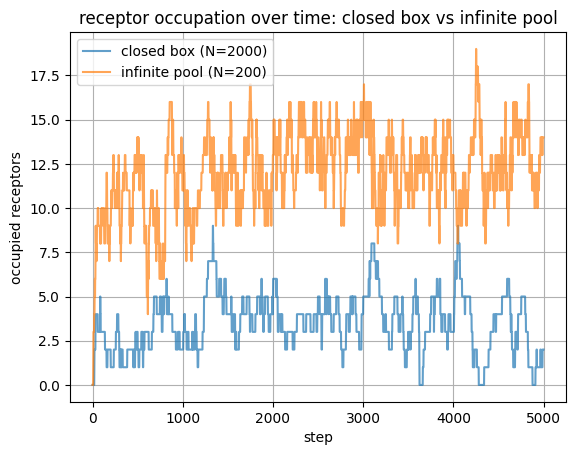

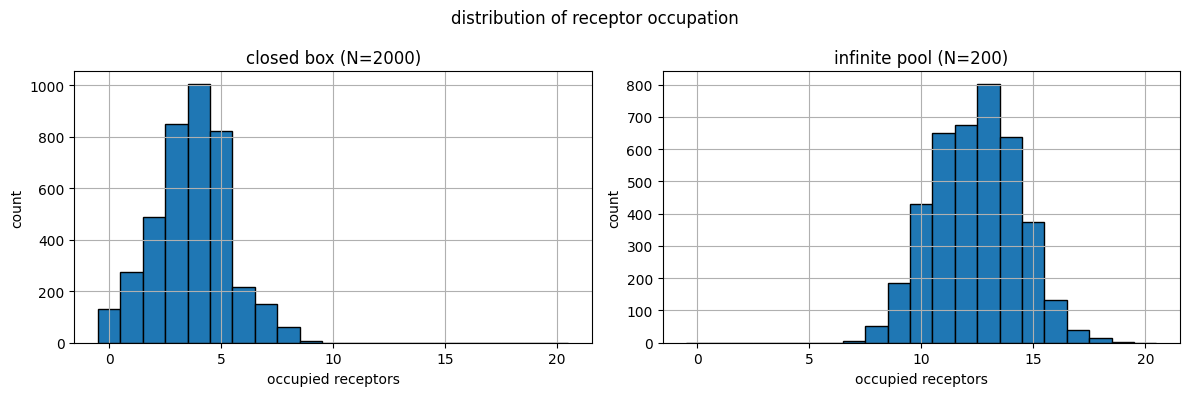


closed box mean occupancy:    0.185
infinite pool mean occupancy: 0.622


In [5]:
L = 100
nrec = 20
pon = 0.01
poff = 0.01

x_rec = np.arange(0, L, np.int32(L / nrec))
y_rec = L / 2 * np.ones(len(x_rec))

print("running closed box...")
N_closed = 2000
coord_c = db.create_in_point(N_closed, [int(L/2), int(L/2)])
coord_rec_c = db.create_receptors(x_rec, y_rec)

for step in range(5000):
    coord_c = db.diffusione(coord_c)
    coord_c = db.p_boundary(coord_c, L)

history_closed = []
for step in range(5000):
    coord_c, coord_rec_c = db.escape(coord_c, coord_rec_c, poff)
    history_closed.append(np.array(coord_rec_c[:, 2]))
    coord_c = db.diffusione(coord_c)
    coord_c = db.p_boundary(coord_c, L)
    coord_c, coord_rec_c = db.receptors(coord_c, coord_rec_c, pon)
    if step % 500 == 0:
        print(f"  closed box step {step}/5000")

history_closed = np.array(history_closed)
print("closed box done!")

print("running infinite pool...")
N_open = 200
coord_o = db.create(N_open, L)
coord_rec_o = db.create_receptors(x_rec, y_rec)

# wait for steady state
for step in range(2000):
    coord_o = db.diffusione(coord_o)
    coord_o = db.check(coord_o, L)
    coord_o = np.vstack((coord_o, db.create(N_open, L)))

history_open = []
for step in range(5000):
    coord_o, coord_rec_o = db.escape(coord_o, coord_rec_o, poff)
    history_open.append(np.array(coord_rec_o[:, 2]))
    coord_o = db.diffusione(coord_o)
    coord_o = db.check(coord_o, L)
    coord_o = np.vstack((coord_o, db.create(N_open, L)))
    coord_o, coord_rec_o = db.receptors(coord_o, coord_rec_o, pon)
    if step % 500 == 0:
        print(f"  infinite pool step {step}/5000")

history_open = np.array(history_open)
print("infinite pool done!")

total_closed = history_closed.sum(axis=1)
total_open = history_open.sum(axis=1)

plt.figure()
plt.plot(total_closed, label='closed box (N=2000)', alpha=0.7)
plt.plot(total_open, label='infinite pool (N=200)', alpha=0.7)
plt.xlabel("step")
plt.ylabel("occupied receptors")
plt.title("receptor occupation over time: closed box vs infinite pool")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(total_closed[1000:], bins=range(nrec + 2), align='left', edgecolor='black')
axes[0].set_title("closed box (N=2000)")
axes[0].set_xlabel("occupied receptors")
axes[0].set_ylabel("count")
axes[0].grid(True)

axes[1].hist(total_open[1000:], bins=range(nrec + 2), align='left', edgecolor='black')
axes[1].set_title("infinite pool (N=200)")
axes[1].set_xlabel("occupied receptors")
axes[1].set_ylabel("count")
axes[1].grid(True)

plt.suptitle("distribution of receptor occupation")
plt.tight_layout()
plt.show()

print(f"\nclosed box mean occupancy:    {history_closed[1000:].mean():.3f}")
print(f"infinite pool mean occupancy: {history_open[1000:].mean():.3f}")

I repeated the same simulation as question 1 but this time with the infinite pool instead of the closed box, and I compared the two results directly. The infinite pool simulation is much slower to run than the closed box, because at every step new particles are added to the box from the walls, so the array of particles keeps growing. To keep the run time reasonable I added 200 particles per step in the pool, against a fixed 2000 particles in the closed box.

The mean occupancy is much higher in the infinite pool: 0.62 against 0.19 in the closed box. But this is not a fair comparison, because the two boxes do not contain the same number of particles. I did not record the particle count in this run, but in the first assignment the pool with 100 particles added per step already contained more than 9000 particles after 5000 steps. So here the pool almost certainly holds many more particles than the closed box, and from questions 2 and 3 more particles means higher occupancy. The line of receptors also starts at the wall, where the particles are injected. So I think the higher occupancy comes from the higher particle density around the receptors and not from the type of box itself. To compare the two cases properly I would have to measure the density around the receptors in both.

In the closed box the number of free particles hardly changes when the receptors bind (at most 20 out of 2000 are trapped), so the ligand is not really limited there. In the plot the occupation fluctuates in both cases.

Overall I think the infinite pool is closer to a realistic biological situation where a cell receptor is surrounded by a constant concentration of ligand molecules coming from outside, while the closed box is an isolated system with a fixed number of ligand molecules.